# Raport: Lista 1

**Autor:** Bartosz Kruszewski

**Data:** 2026-10-09


In [218]:
#| include: false

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Latex, display
from scipy import stats

\newpage

## Metryki

Metryki za pomocą których będziemy badać własności estymatorów to:

- obiążenie _(bias)_
- wariancja _(var)_
- błąd średniokwadratowy _(mse)_

Będą one wyliczane przez następującą funkcję:


In [219]:
def calculate_metrics(estimates, true_val):
    bias = np.mean(estimates) - true_val
    var = np.var(estimates, ddof=1)
    mse = np.mean((estimates - true_val) ** 2)
    return bias, var, mse

## Estymatory

Wszystkie wykorzystywane w zadaniach estymatory zostały zapisane jako funkcje z przedrostkiem `est_`.

Jako wagi do estymatora _(iii) z zadania 1_ zostały wykorzystane wagi trójkątne (nieujemne), czyli wagi faworyzujące środkowe element z rozkładu. Wagi zostały znormalizowane, żeby spełniały warunek sumowania się do 1. Zostały wybrane ze względu na symetrię, która oddaje część natury rozkładu normalnego, a nie są tak trywialne jak wagi jednorodne.

Wagi do estymatora _(iv) z zadania 1_ zostały zapisane zgodnie z treścią. Natomiast nie sumowały się one do 1. Może to powodować znaczne obciążenie estymatora. Stąd wagi zostały znormalizowane.

Jako własny estymator _(vii) z zadania 1_ wybrałem średnią ucinaną (średnia z odrzuceniem niewielkiej części wartości skrajnych). Jest to metoda łącząca cechy średniej arytmetycznej oraz mediany.


\newpage

In [ ]:
def est_mean(X):  # średnia arytmetyczna
    return np.mean(X, axis=1)


def est_median(X):  # mediana
    return np.median(X, axis=1)


def est_weighted_custom(X):  # średnia ważona z własnymi wagami
    n = X.shape[1]

    # wyliczenie wag trójkątnych
    w = np.arange(1, n + 1, dtype=float)
    w = np.minimum(w, n + 1 - w)  # zamiania na wektor trójkątny
    weights = w / np.sum(w)  # normalizacja wag

    return np.dot(X, weights)


def est_order_stats(X):  # średnia ważona z wagami ze wzoru
    n = X.shape[1]
    X_sorted = np.sort(X, axis=1)

    u = np.linspace(0.0, 1.0, n + 1)

    with np.errstate(divide="ignore"):
        z = stats.norm.ppf(u)
    dens = stats.norm.pdf(z)

    # dodana normalizacja
    weights = np.abs(dens[:-1] - dens[1:])
    weights = weights / np.sum(weights)

    return np.dot(X_sorted, weights)


def est_harmonic_mean(X):  # średnia harmoniczna
    n = X.shape[1]

    # zignorowanie błędów dzielenia przez zero
    with np.errstate(divide="ignore", invalid="ignore"):
        inv_sum = np.sum(1.0 / X, axis=1)
        res = n / inv_sum
    return res


def est_power_mean_3(X):  # średnia potęgowa
    # rozbicie na abs, aby uniknąć problemów z pierwiastkiem z liczby ujemnej
    mean_cube = np.mean(X**3, axis=1)
    return np.sign(mean_cube) * np.abs(mean_cube) ** (1.0 / 3.0)


def est_trimmed_mean(X, trim_ratio=0.10):  # średnia ucinana
    n = X.shape[1]
    k = int(trim_ratio * n)
    if k == 0:
        return np.mean(X, axis=1)
    X_sorted = np.sort(X, axis=1)
    return np.mean(X_sorted[:, k : n - k], axis=1)


def est_sample_variance(X):  # wariancja z próby
    return np.var(X, axis=1, ddof=1)


def est_variance_around_median(X):  # wariancja wokół mediany
    n = X.shape[1]
    med = np.median(X, axis=1, keepdims=True)
    return np.sum((X - med) ** 2, axis=1) / (n - 1)


def est_median_squared_dev(X):  # mediana kwadratów odchyleń od mediany
    mean = np.mean(X, axis=1, keepdims=True)
    sq_deviations = (X - mean) ** 2
    return np.median(sq_deviations, axis=1)

In [221]:
#| include: false


def run_simulation(
    scenarios,
    dist_func,
    dist_name,
    estimators,
    M=10000,
    plot_exclude=(),
    include_mse_plot=False,
    plots_in_row=3,
):
    all_metrics = []
    all_samples = []

    # symulacja dla każdego scenariusza
    for i, sc in enumerate(scenarios):
        n, loc, scale, theta = sc["n"], sc["loc"], sc["scale"], sc["theta"]
        params = f"loc={loc}, scale={scale}, theta={theta}"
        panel_label = f"n={n}, {params}"

        X = dist_func(loc=loc, scale=scale, size=(M, n))
        estimated = {est.__name__[4:]: est(X) for est in estimators}

        for name, vals in estimated.items():
            bias, var, mse = calculate_metrics(vals, theta)
            all_metrics.append(
                {
                    "scenario_idx": i,
                    "Scenariusz": params,
                    "n": n,
                    "Estymator": name,
                    "Obciążenie": bias,
                    "Wariancja": var,
                    "MSE": mse,
                }
            )

        plot_ests = {k: v for k, v in estimated.items() if k not in plot_exclude}
        df_s = pd.DataFrame(plot_ests).melt(var_name="Estymator", value_name="Wartość")
        df_s["Panel"] = panel_label
        df_s["theta"] = theta
        all_samples.append(df_s)

    metrics_df = pd.DataFrame(all_metrics)

    # wykres MSE vs n
    if include_mse_plot:
        filtered = metrics_df[~metrics_df["Estymator"].isin(plot_exclude)]

        g_mse = sns.relplot(
            data=filtered,
            x="n",
            y="MSE",
            hue="Estymator",
            col="Scenariusz",
            kind="line",
            marker="o",
            col_wrap=2,
            facet_kws={"sharey": False},
        )
        g_mse.set_titles(col_template="{col_name}")
        g_mse.fig.suptitle("MSE vs n")
        g_mse.fig.subplots_adjust(top=0.9)
        plt.show()

    # wykres rozkładów estymatorów
    plot_df = pd.concat(all_samples, ignore_index=True)
    theta_map = plot_df.groupby("Panel")["theta"].first()

    g = sns.catplot(
        data=plot_df,
        x="Estymator",
        y="Wartość",
        col="Panel",
        kind="box",
        showmeans=True,
        col_wrap=plots_in_row,
        sharey=False,
    )
    g.set_titles(col_template="{col_name}")

    for ax in g.axes.flat:
        label = ax.get_title().strip()
        if label in theta_map:
            ax.axhline(
                theta_map[label],
                color="red",
                ls="--",
                label=f"$\\theta$={theta_map[label]}",
            )
            ax.legend()
        ax.tick_params(axis="x", rotation=15)

    g.fig.suptitle(f"Rozkład estymatorów ({dist_name} M={M})")
    g.fig.subplots_adjust(top=0.9)
    plt.show()

    # tabela
    display(Latex(r"\begingroup\small\renewcommand{\arraystretch}{0.75}"))
    display(
        metrics_df.sort_values(by=["scenario_idx", "Estymator"])
        .drop(columns=["scenario_idx"])
        .set_index(["Scenariusz", "n", "Estymator"])
        .style.set_caption(f"Metryki estymatorów ({dist_name} M={M})")
        .format(precision=5)
    )
    display(Latex(r"\endgroup"))

\newpage


## Zadanie 1

Wnioski:

- średnia arytmetyczna pomimo swojej prostoty sprawdza się bardzo dobrze (zgodnie z teorią)
- mediana ma nieco wyższą wariancję od średniej arytmetycznej, ale też jest dość dobra
- średnia ucinana, zgodnie z przewidywaniami, plasuje się pomiędzy średnią arymetyczną a medianą
- średnie ważone _(po znormalizowaniu)_ plasuje się podobnie jak średnia ucinana, natomiast bez normalizacji były znacząco obciążone
- średnia harmoniczna zupełnie nie nadaje się ze względu na generowanie drastycznego błędu dla wartości bliskich 0
- średnia potęga ma sporą wariancję i jest obciążona dla większych theta
- MSE maleje względem zwiększania liczby prób n. Dodałem wykresy dla zobrazowania tego zjawiska.

Z wykresów celowo została wykluczona średnia harmoniczna, ponieważ psuła widoczność całego wykresu. Wartości wyliczonych dla niej metryk są wypisane w tabelce.


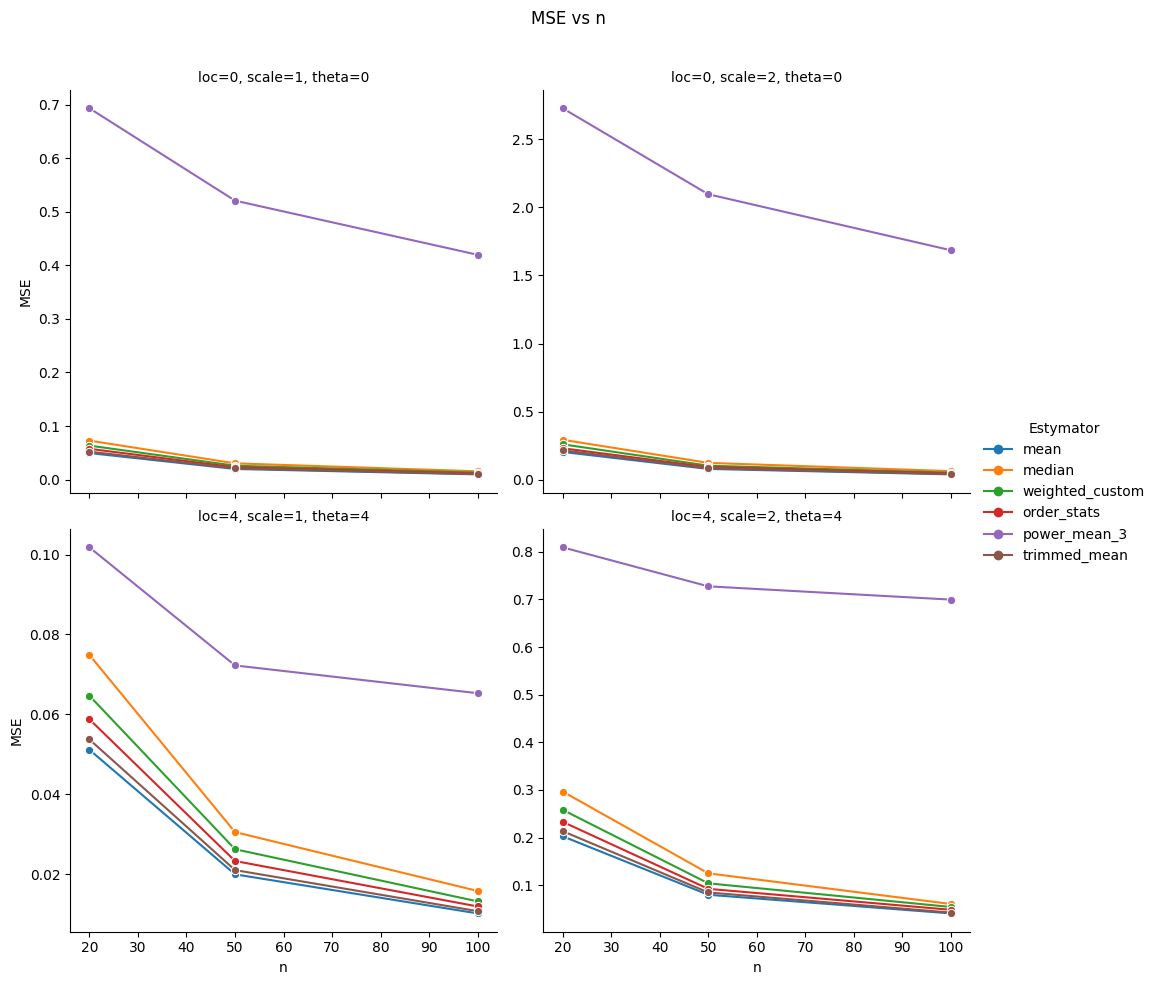

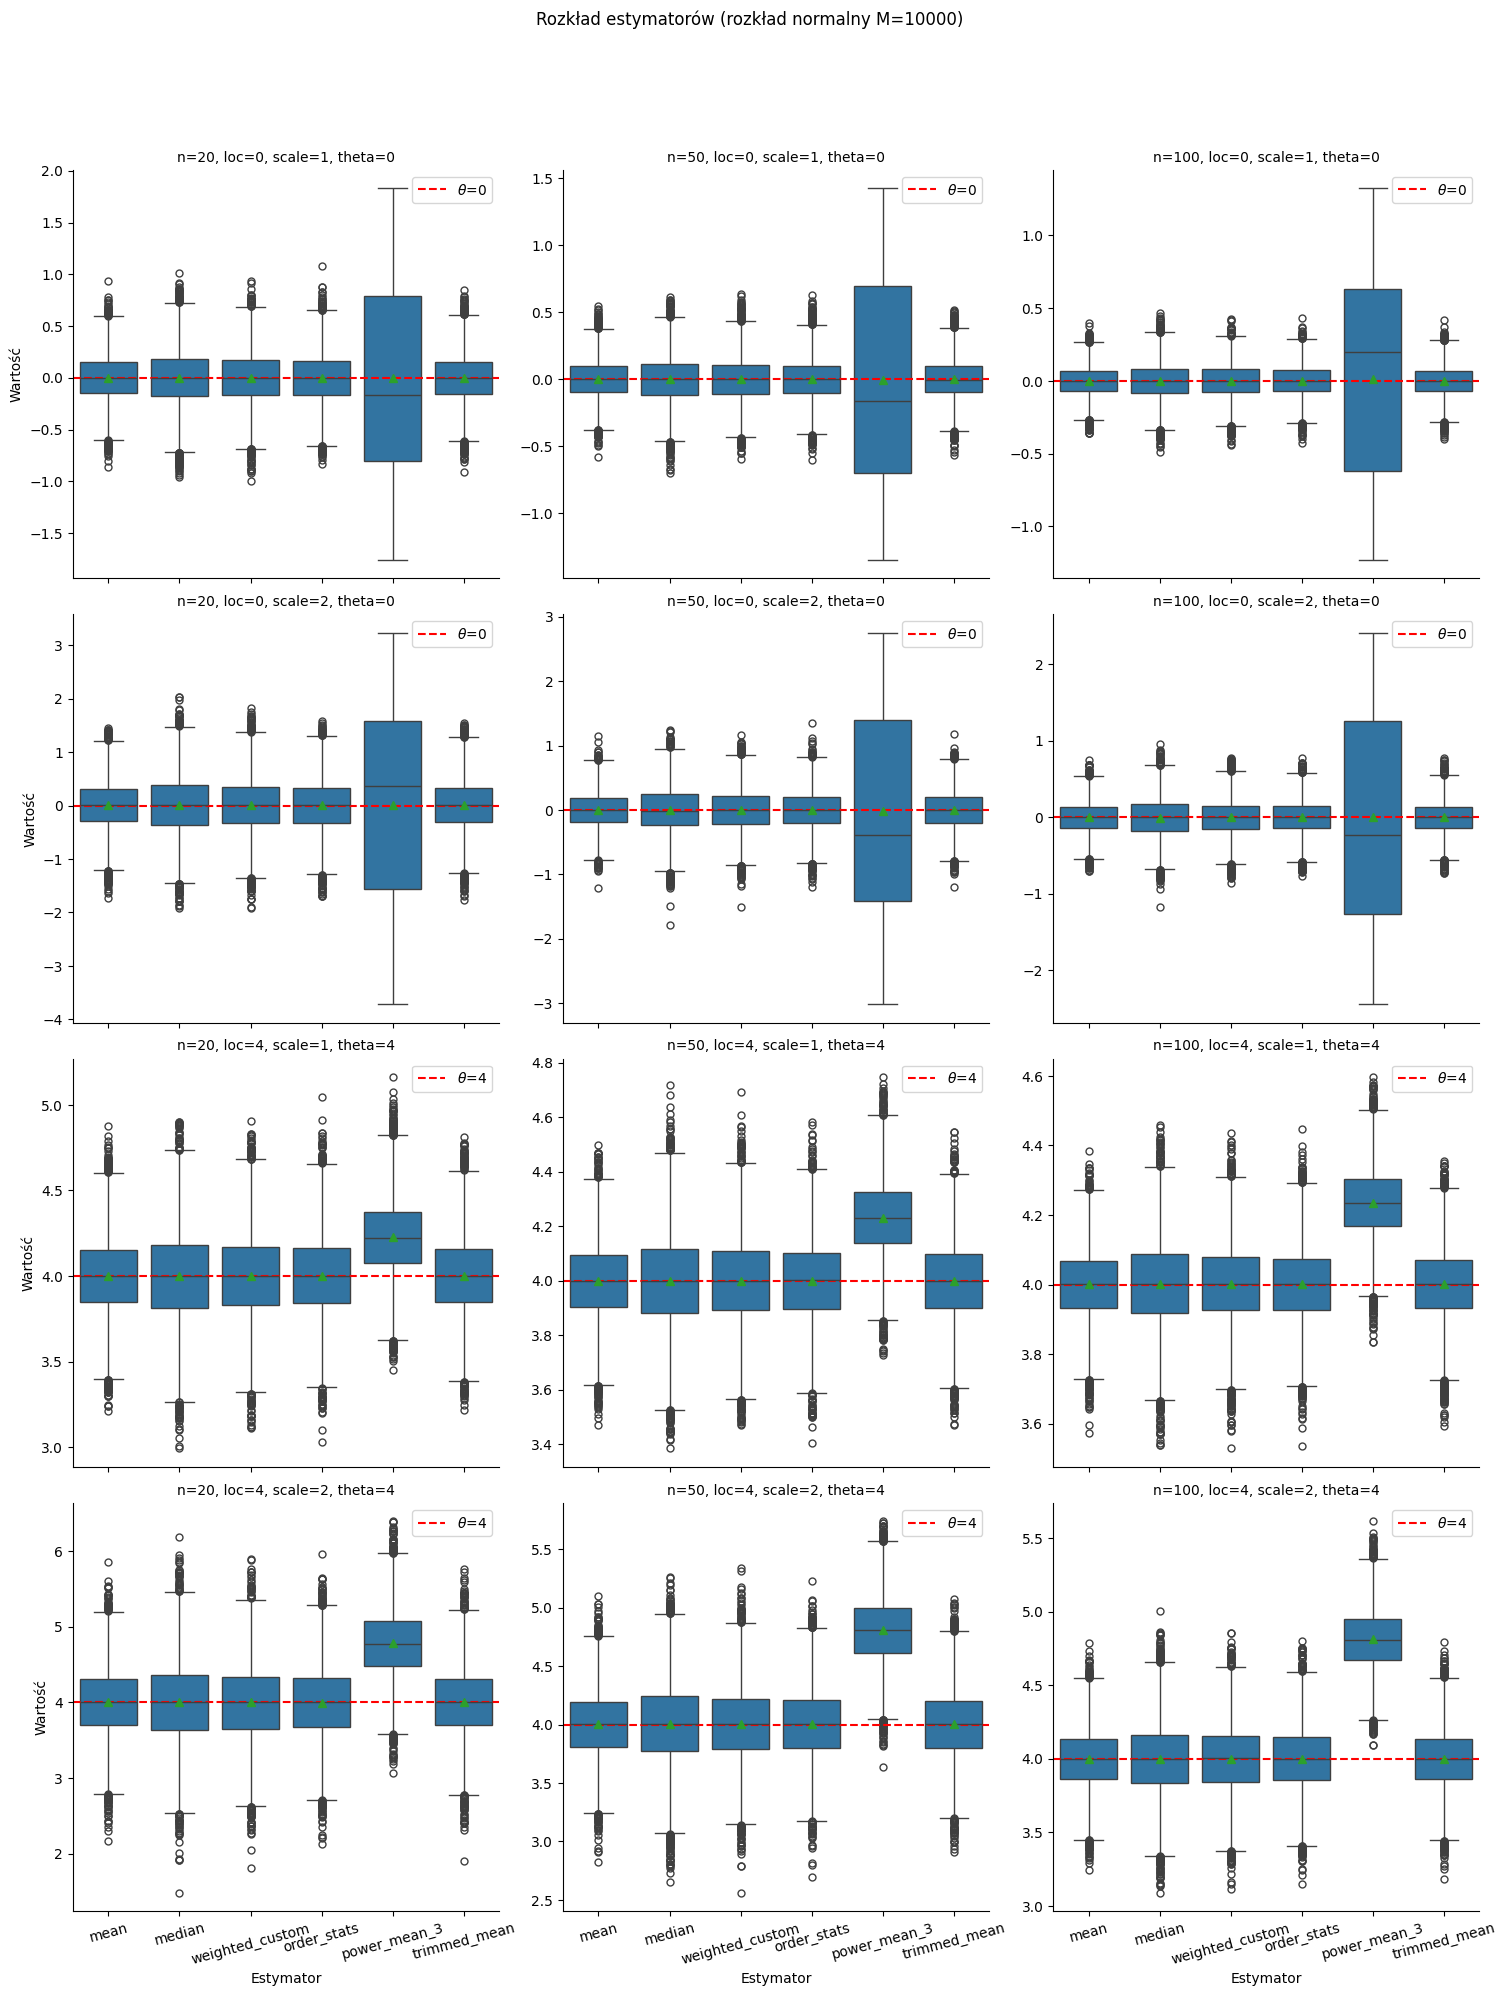

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [222]:
#| echo: false
#| output: true

run_simulation(
    scenarios=[
        {"n": n, "loc": theta, "scale": sigma, "theta": theta}
        for theta in [0, 4]
        for sigma in [1, 2]
        for n in [20, 50, 100]
    ],
    dist_func=np.random.normal,
    dist_name="rozkład normalny",
    estimators=[
        est_mean,
        est_median,
        est_weighted_custom,
        est_order_stats,
        est_harmonic_mean,
        est_power_mean_3,
        est_trimmed_mean,
    ],
    plot_exclude=("harmonic_mean",),
    include_mse_plot=True,
)

\newpage


## Zadanie 2

Wnioski:

- dla rozkładu normalnego oraz logistycznego średnia artymetyczna oraz mediana dobrze się sprawdzają i dają podobne rezultaty
- dla rozkładu Cauchiego średnia arytmetyczna daje gigantyczny błąd, natomiast mediana nadal sprawdza się bardzo dobrze


\newpage


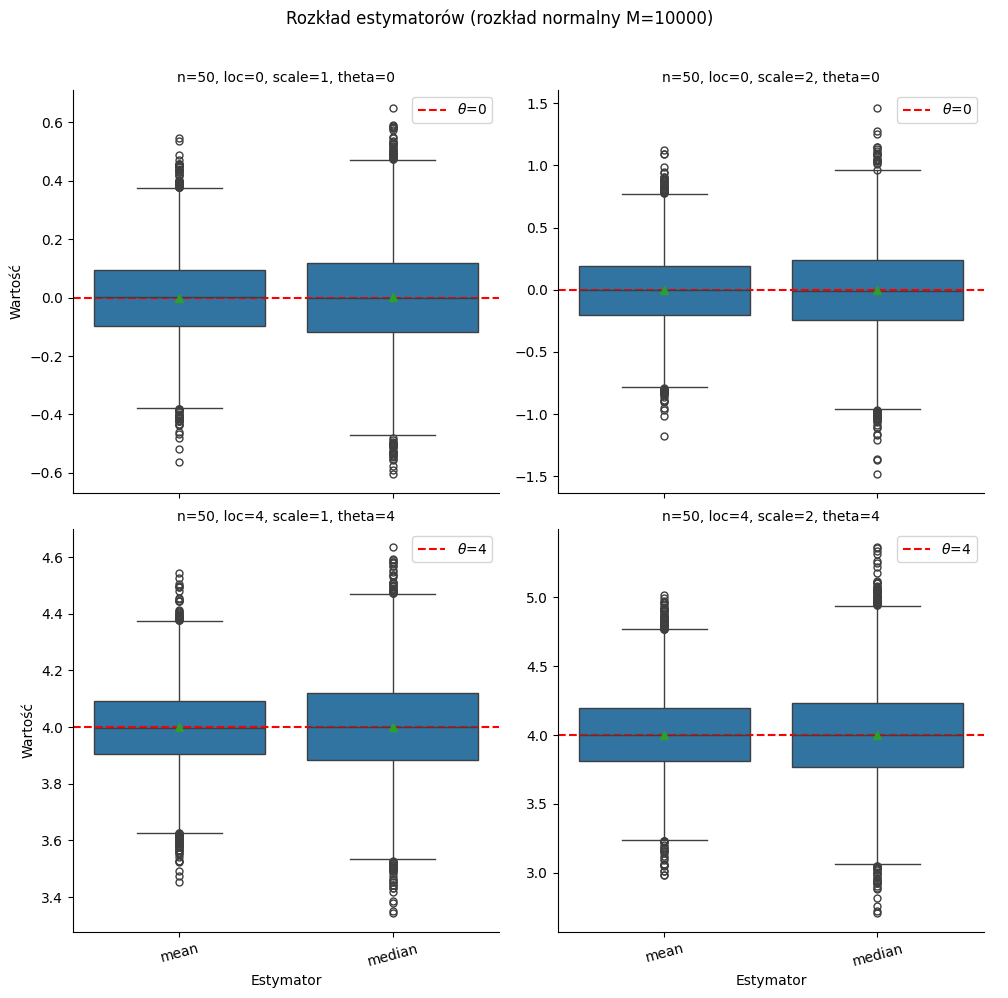

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

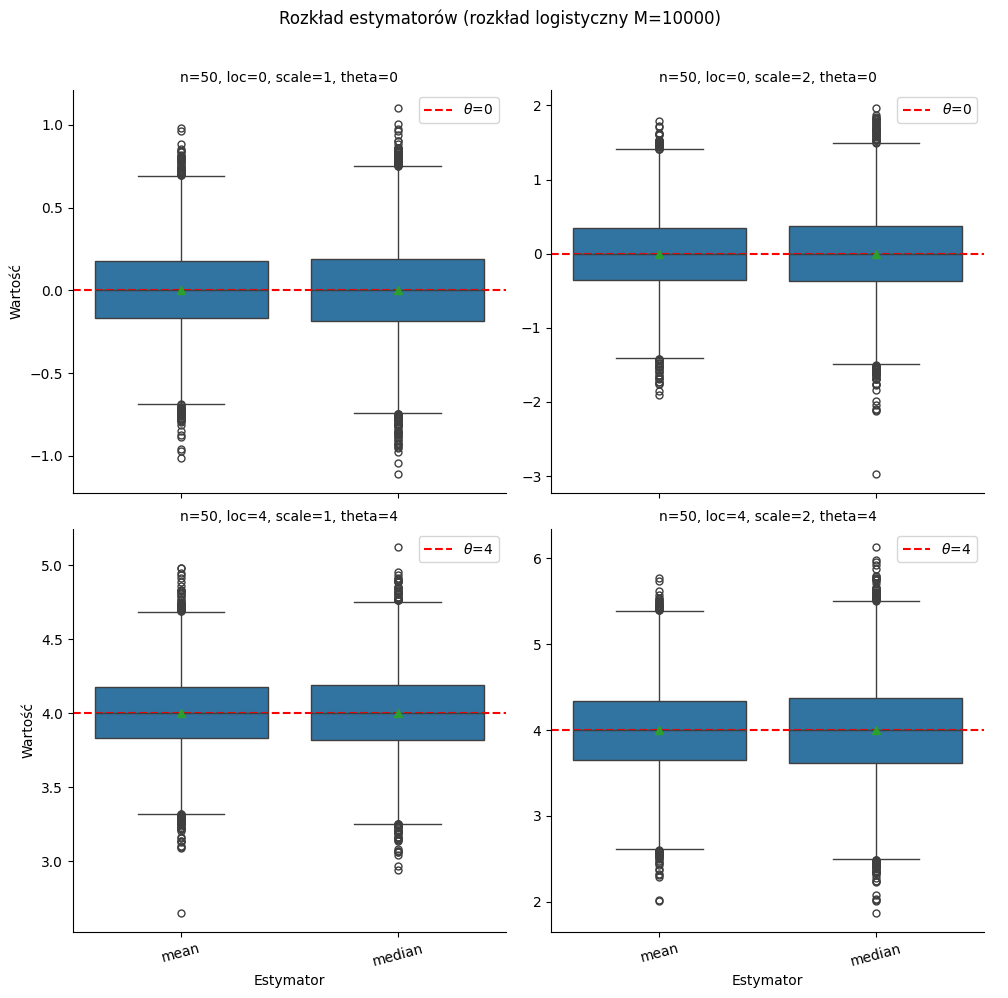

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

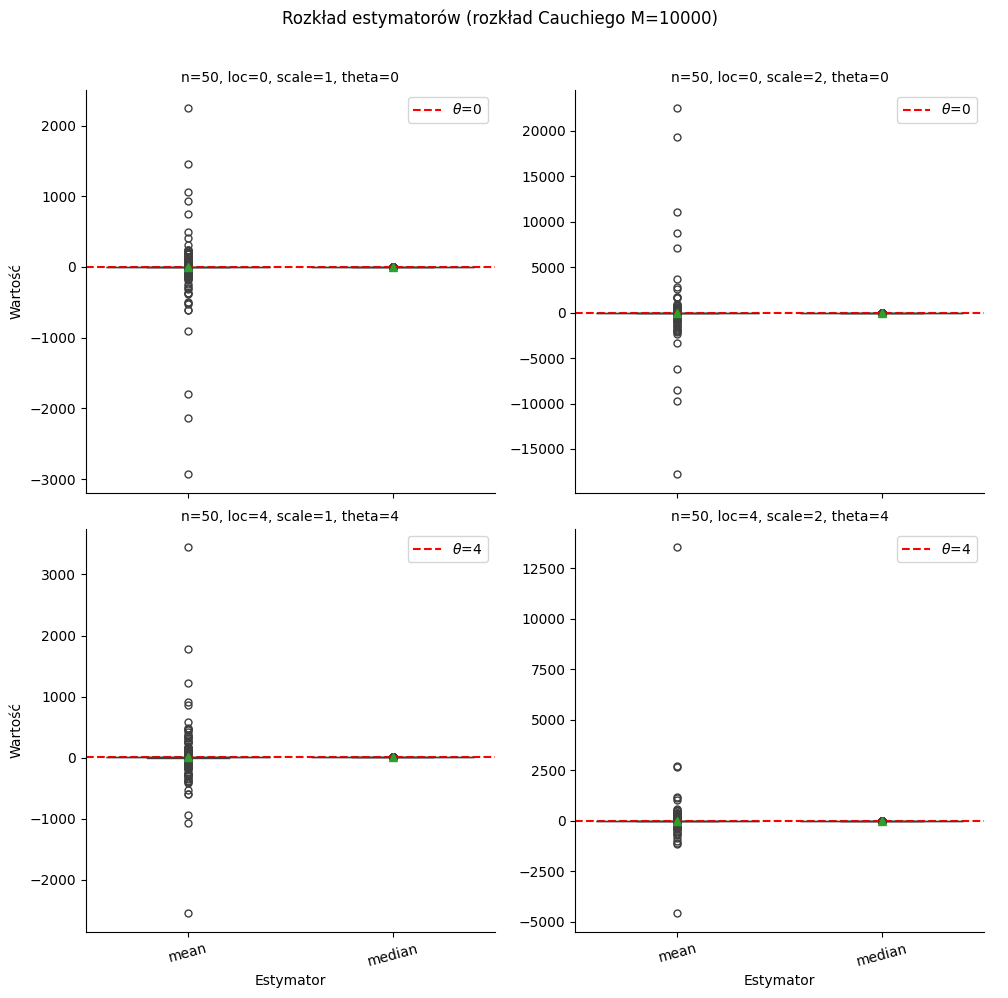

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [223]:
#| echo: false
#| output: true

for dist_func, dist_name in zip(
    [np.random.normal, np.random.logistic, stats.cauchy.rvs],
    ["rozkład normalny", "rozkład logistyczny", "rozkład Cauchiego"],
):
    run_simulation(
        scenarios=[
            {"n": 50, "loc": theta, "scale": sigma, "theta": theta}
            for theta in [0, 4]
            for sigma in [1, 2]
        ],
        dist_func=dist_func,
        dist_name=dist_name,
        estimators=[est_mean, est_median],
        plots_in_row=2,
    )


\newpage


## Zadanie 3

Wnioski:

- średnia arytmetyczna jest obarczona dużym obciążeniem, proporcjonalnym do wielkości zaburzonej próby. Natomiast wariancja nie ulega pogorszeniu, jest ona mniejsza niż w przypadku mediany
- mediana bardzo dobrze znosi nawet mocno zaburzoną próbę, ma trochę większa wariancję od średniej arytmetycznej, natomiast biorąc pod uwagę MSE wypada zdecydowanie lepiej


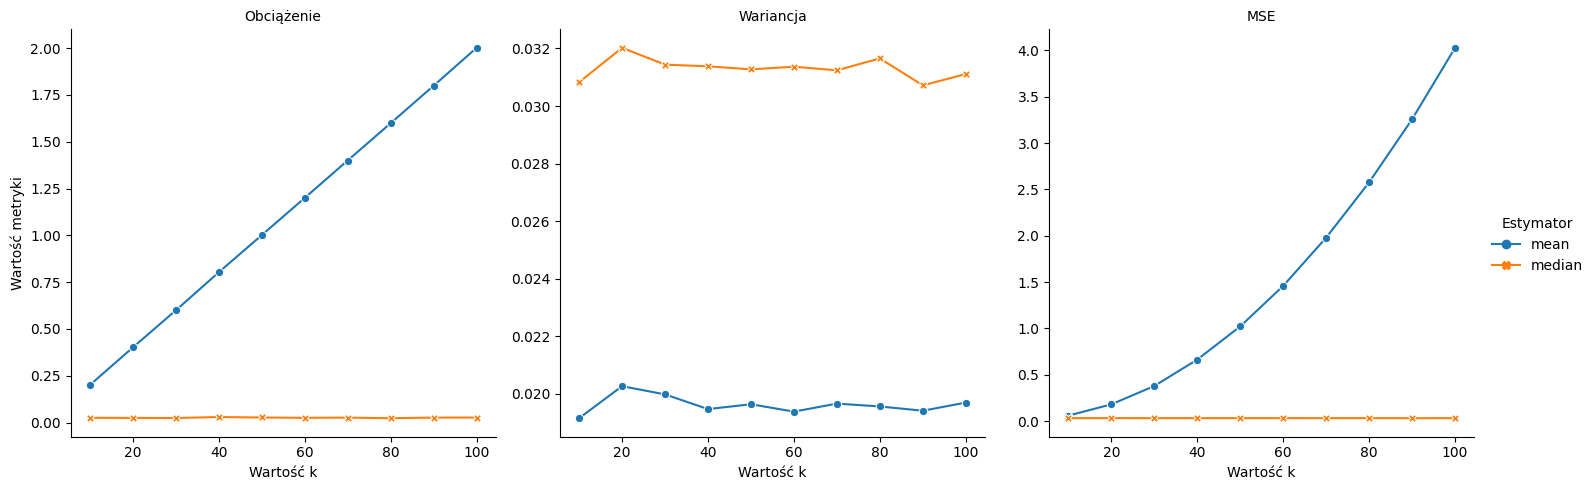

In [224]:
#| echo: false
#| output: true
#| fig.align: center

M, N = 10000, 50

metrics = pd.DataFrame(
    [
        {"k": k, "Estymator": est.__name__[4:], "Metryka": m, "Wartość": val}
        for k in range(10, 101, 10)
        for X in [np.hstack((np.random.normal(size=(M, N - 1)), np.full((M, 1), k)))]
        for est in [est_mean, est_median]
        for m, val in zip(
            ["Obciążenie", "Wariancja", "MSE"], calculate_metrics(est(X), 0)
        )
    ]
)

display(
    metrics.pivot(index="k", columns=["Metryka", "Estymator"], values="Wartość")
    .reindex(columns=["Obciążenie", "Wariancja", "MSE"], level=0)
    .style.format(precision=5)
)

g = sns.relplot(
    data=metrics,
    x="k",
    y="Wartość",
    hue="Estymator",
    style="Estymator",
    col="Metryka",
    kind="line",
    markers=True,
    dashes=False,
    facet_kws={"sharey": False},
)
g.set_axis_labels("Wartość k", "Wartość metryki")
g.set_titles(col_template="{col_name}")
plt.show()

\newpage


## Zadanie 4

Wnioski:

- wariancja z próby oraz wariancja wokół mediany sprawdzają się bardzo dobrze, z lekką przewagą wariancji z próby
- mediana kwadratów odchyleń od średniej ma znaczące obciążenie i niewielką wariancję, natomiast MSE jest zdecydowanie większe od pozostałych estymatorów


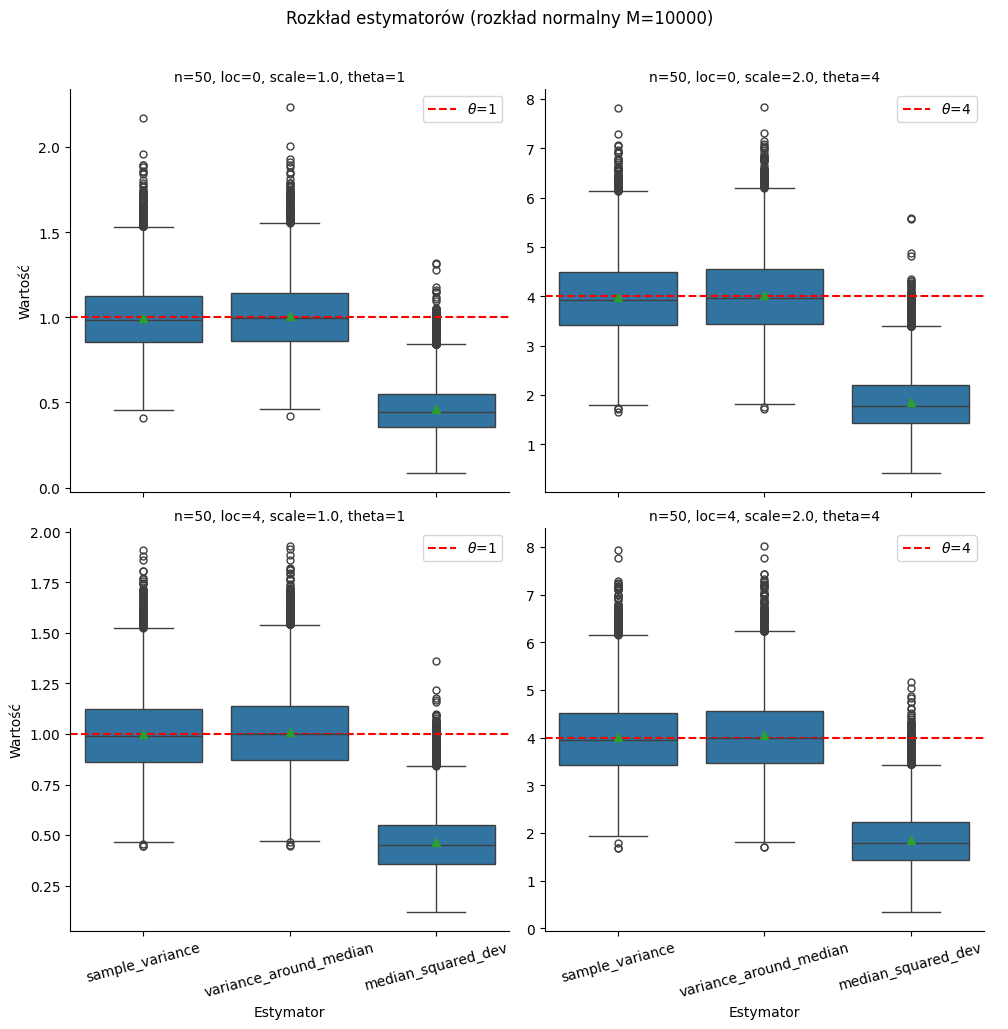

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [225]:
#| echo: false
#| output: true
#| fig.align: center

run_simulation(
    scenarios=[
        {"n": 50, "loc": mu, "scale": np.sqrt(theta), "theta": theta}
        for mu in [0, 4]
        for theta in [1, 4]
    ],
    dist_func=np.random.normal,
    dist_name="rozkład normalny",
    estimators=[
        est_sample_variance,
        est_variance_around_median,
        est_median_squared_dev,
    ],
    plots_in_row=2,
)